# LASSI - CUDA → SYCL Translation (v3 pipeline)

This notebook is a **minimal** refactor of the original v3 pipeline notebook.

Success criteria for this notebook:

1. Build + run the original CUDA XSBench and print its stdout.
2. Translate the CUDA kernel source to SYCL using the **base self-correction compile/execute loop** (no energy-efficiency optimization loop).
3. Compile + run the generated SYCL code using a **separate SYCL toolchain**.

Notes:

- The CUDA source compiles as-is via the XSBench Makefile.
- The generated SYCL code is compiled via a generic Makefile in the experiment directory (written by the pipeline) using the configured SYCL compiler.


In [1]:
import os
import json
import csv
import time
import shutil
from datetime import datetime
from zoneinfo import ZoneInfo

os.chdir('/home/vchirio/Desktop/LASSI-EE')
print('CWD:', os.getcwd())

# Ensure CUDA Toolkit nvcc is on PATH for Stage 0 (XSBench CUDA build).
# NOTE: Jupyter kernels may not inherit your interactive shell PATH.
os.environ['PATH'] = '/usr/local/cuda/bin:' + os.environ.get('PATH', '')
print('nvcc on PATH:', shutil.which('nvcc'))

import lassi.llm_config
import lassi.pipeline_v3

from lassi.prompt_dictionary import PromptDictionary
from lassi.gpu_detector import detect_gpu_vendors
from lassi.sycl_toolchain import get_sycl_toolchain

prompts = PromptDictionary()

vendors = detect_gpu_vendors()
if not vendors:
    raise SystemExit('Pipeline stopped - no GPU hardware found')

detected_vendor = vendors[0]['vendor']
gpu_count = vendors[0]['count']
print(f'Detected: {detected_vendor.upper()} with {gpu_count} GPU(s)')

sycl_tc = get_sycl_toolchain()
print('SYCL toolchain:', sycl_tc)


CWD: /home/vchirio/Desktop/LASSI-EE
nvcc on PATH: /usr/local/cuda/bin/nvcc
Detected: NVIDIA with 1 GPU(s)
SYCL toolchain: SYCLToolchain(compiler='/home/vchirio/adaptivecpp/bin/acpp', cxxflags='-O3 -std=c++17', ldflags='', env_hint='export PATH=/home/vchirio/adaptivecpp/bin:$PATH')


## Experiment setup

We run XSBench CUDA first, then translate `Main.cu` to SYCL and attempt to compile/run the SYCL output.


In [2]:
def init_data_collection(dir_path, fieldnames, filename='lassi-translate_pipeline_data.csv'):
    os.makedirs(dir_path, exist_ok=True)
    fp = os.path.join(dir_path, filename)
    if not os.path.exists(fp):
        with open(fp, 'w', newline='') as f:
            writer = csv.DictWriter(f, fieldnames=fieldnames)
            writer.writeheader()
    return fp


In [3]:
def experimental_setup_translate_xsbench_cuda_to_sycl():
    with open('source_apps.json', 'r') as f:
        source_apps = json.load(f)

    source_collection = 'Miniapps'
    source_app = 'XSBench'

    source_folder = source_apps[source_collection]['source_folder']
    app_folder_name = source_apps[source_collection][source_app]['app_folder']
    lines_of_code = source_apps[source_collection][source_app]['code_lines']

    app_name = source_app
    file_name = 'Main'

    # Translation: CUDA -> SYCL
    source_lang = 'CUDA'
    target_lang = 'SYCL'

    # We only want: test source, then base self-correction compile/execute loop for SYCL
    test_code_first = True
    yes_execute = True
    power_measure = False

    # Disable all energy-efficiency iteration logic
    yes_power_feedback = False
    baseline_oneshot_goal = True
    use_self_prompting = False
    vary_llm_temp = False

    # LLM config
    model = 'gpt52'
    model_coder = 'gpt52'
    model_judge = 'gpt52'
    num_ctx = 200000
    num_ctx_coder = 200000

    # LLM source selection (same logic as original notebook)
    if model in ['gpt52', 'gpt5','gpt35','gpt35large','gpt4','gpt4large','gpt4turbo','gpt4o','gpt4olatest','gpt41',
                 'gpto1preview','gpto1mini','gpto3mini','gpto4mini','claudesonnet4']:
        llm_source = 'argo'
    elif model in ['gpt-oss-120b','qwen-3-coder-480b']:
        llm_source = 'cerebras'
    elif ('GGUF' in model and 'hf.co' not in model):
        llm_source = 'lmstudio'
    else:
        llm_source = 'ollama'

    # Build/run for CUDA source (Makefile)
    make_script = True
    build_script = False
    code_build_script = ''

    code_compiler = 'make'
    code_compiler_kwds = '-j SM_VERSION=80 CFLAGS=-std=c++17'

    # SYCL compilation toolchain (used for generated SYCL code only)
    sycl_compiler = sycl_tc.compiler
    sycl_compiler_kwds = f"{sycl_tc.cxxflags} {sycl_tc.ldflags}".strip()

    # Execute params
    # Use the app's default parameters from source_apps.json so Stage 0 (CUDA) and
    # Stage 1+ (generated SYCL) run with the exact same CLI args for checksum comparison.
    exe_input_parameters = source_apps[source_collection][source_app]['app_params'] if yes_execute else ['']

    experiment = f'exp_xsbench_translate_cuda_to_sycl_{model_coder}_{detected_vendor.upper()}'
    display_response = True
    test_with_error = False
    generate_test_case = False
    verifyprompt = False

    # Context flags (unused for this minimal translation run)
    use_context = False
    use_context_summaries_only = True
    few_shot_learning = False
    run_code_analysis = False

    # Minimal data fields (keep compatible shape with pipeline writer)
    DATAFIELDNAMES = [
        'trial_number','timestamp','experiment','gpu_vendor','app_name','code_line_count',
        'llm','llm_coder','llm_judge',
        'source_stdout',
        'sycl_compile_ok','sycl_run_ok','sycl_stdout',
        'pipeline_runtime_min'
    ]

    return (
        app_folder_name, app_name, file_name, lines_of_code,
        source_lang, target_lang,
        model, model_coder, model_judge,
        num_ctx, num_ctx_coder,
        llm_source, use_context, use_context_summaries_only, few_shot_learning, run_code_analysis,
        source_folder,
        # CUDA build
        code_compiler, code_compiler_kwds,
        # SYCL build
        sycl_compiler, sycl_compiler_kwds,
        build_script, make_script, code_build_script,
        yes_execute, exe_input_parameters,
        experiment, display_response, test_with_error, generate_test_case,
        power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp,
        verifyprompt, DATAFIELDNAMES, detected_vendor.upper()
    )


In [4]:
(
    app_folder_name, app_name, file_name, lines_of_code,
    source_lang, target_lang,
    model, model_coder, model_judge,
    num_ctx, num_ctx_coder,
    llm_source, use_context, use_context_summaries_only, few_shot_learning, run_code_analysis,
    source_folder,
    cuda_code_compiler, cuda_code_compiler_kwds,
    sycl_code_compiler, sycl_code_compiler_kwds,
    build_script, make_script, code_build_script,
    yes_execute, exe_input_parameters,
    experiment, display_response, test_with_error, generate_test_case,
    power_measure, test_code_first, yes_power_feedback, baseline_oneshot_goal, use_self_prompting, vary_llm_temp,
    verifyprompt, DATAFIELDNAMES, gpu_vendor
) = experimental_setup_translate_xsbench_cuda_to_sycl()

print('Experiment:', experiment)
print('CUDA build:', cuda_code_compiler, cuda_code_compiler_kwds)
print('SYCL build:', sycl_code_compiler, sycl_code_compiler_kwds)


Experiment: exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA
CUDA build: make -j SM_VERSION=80 CFLAGS=-std=c++17
SYCL build: /home/vchirio/adaptivecpp/bin/acpp -O3 -std=c++17


In [5]:
# Load input CUDA code (XSBench Main.cu)
input_code_folder = f"{source_folder}/{app_folder_name}/"
input_code_filename = file_name
input_code_extension = 'cu'

source_file_directory = 'source_codes/' + input_code_folder
source_file_path = os.path.abspath(source_file_directory + input_code_filename + '.' + input_code_extension)

with open(source_file_path, 'r') as f:
    input_code = f.read()

print('Loaded source:', source_file_path)
print('Source LOC:', len(input_code.splitlines()))


Loaded source: /home/vchirio/Desktop/LASSI-EE/source_codes/Miniapps/XSBench/cuda/Main.cu
Source LOC: 2201


In [6]:
# Output directories
output_code_directory = f"generated_codes/{source_folder}/{app_folder_name}/sycl"
output_code_file_name = input_code_filename

now = datetime.now(ZoneInfo('America/Chicago'))
dt_string = now.strftime('%m-%d-%Y_t%H_%M_%S')
experiment_data_directory = os.path.abspath(f"generated_codes/experiment/{experiment}__{dt_string}")
experiment_data_file_object = init_data_collection(experiment_data_directory, DATAFIELDNAMES)

experiment_data = dict.fromkeys(DATAFIELDNAMES, None)
experiment_data['gpu_vendor'] = str(gpu_vendor)
experiment_data['experiment'] = experiment
experiment_data['app_name'] = app_name
experiment_data['code_line_count'] = lines_of_code
experiment_data['llm'] = model
experiment_data['llm_coder'] = model_coder
experiment_data['llm_judge'] = model_judge

meta_data_file = '***** EXPERIMENT CONFIGURATION SUMMARY *****\n'
meta_data_file += f'\nGPU Vendor: {gpu_vendor}'
meta_data_file += f'\nDate-time: {dt_string}'
meta_data_file += f'\nApplication: {app_folder_name}'
meta_data_file += f'\n\nLLM Source: {llm_source}'
meta_data_file += f'\nModel: {model}'
meta_data_file += f'\nModel coder: {model_coder}'
meta_data_file += f'\nModel judge: {model_judge}'
meta_data_file += f'\n\nPower measurement: {power_measure}'
print(meta_data_file)


***** EXPERIMENT CONFIGURATION SUMMARY *****

GPU Vendor: NVIDIA
Date-time: 01-16-2026_t21_30_48
Application: XSBench/cuda

LLM Source: argo
Model: gpt52
Model coder: gpt52
Model judge: gpt52

Power measurement: False


## Run pipeline

This calls the v3 pipeline, but with translation prompts and with power/EE loops disabled.



----- WELCOME TO PIPELINE v3! CODE -----

🔍 Detected GPU vendor: NVIDIA

----- GPU Memory Status:
 GPU 0: 449 MiB used, 15926 MiB free, 16376 MiB total

----- GPU State:
clocks.current.graphics [MHz], clocks.current.sm [MHz], power.draw [W], pstate
210 MHz, 210 MHz, 4.19 W, P8


*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


----- SOURCE CODE: Test compile and execute -----

Test compile the original source code: /home/vchirio/Desktop/LASSI-EE/source_codes/Miniapps/XSBench/cuda/Main.cu
Make - current dir: /home/vchirio/Desktop/LASSI-EE
Running: make clean in /home/vchirio/Desktop/LASSI-EE/source_codes/Miniapps/XSBench/cuda
STDOUT:
rm -rf XSBench Main.o

Running: make -j SM_VERSION=80 CFLAGS=-std=c++17 in /home/vchirio/Desktop/LASSI-EE/source_codes/Miniapps/XSBench/cuda
STDOUT:
nvcc -std=c++17 -c Main.cu -o Main.o
nvcc -std=c++17 Main.o -o XSBench -lm

STDERR:


Make build/Compilation of code successful!


Test executing the compiled original source code: XSBench
🔍 Using N

Waiting for the system to settle down for 1 seconds...: 100%|██████████| 1/1 [00:01<00:00,  1.00s/it]


executable_file:  XSBench
initial_dir:  /home/vchirio/Desktop/LASSI-EE/source_codes/Miniapps/XSBench/cuda
directory_path:  
executable:  XSBench
exe_input_parameters:  ['-m', 'event', '-l', '100000000']
Working directory: /home/vchirio/Desktop/LASSI-EE/source_codes/Miniapps/XSBench/cuda
Execute command: ['./XSBench', '-m', 'event', '-l', '100000000']

running: executable -  XSBench

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

                   __   __ ___________                 _                        
                   \ \ / //  ___| ___ \               | |                       
                    \ V / \ `--.| |_/ / ___ _ __   ___| |__                     
                    /   \  `--. \ ___ \/ _ \ '_ \ / __| '_ \                    
                   / /^\ \/\__/ / |_/ /  __/ | | | (__| | | |                   
                   \/   \/\____/\____/ \___|_| |_|\___|_| |_|                   

                    Developed at Argonne National Laboratory
      

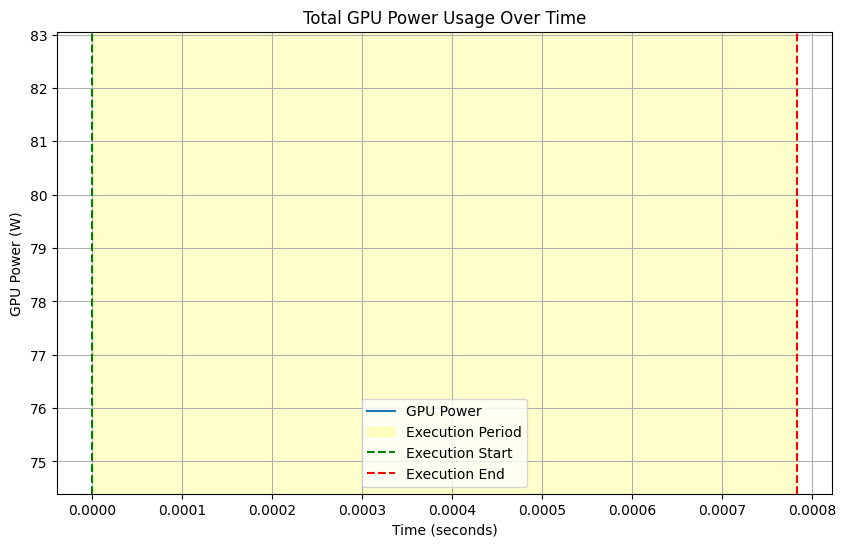

Start time: 0 -- End time: 0.001
Not enough data points to calculate energy consumption.
Total GPU energy consumption for idle__gpu_net_power_results.csv:
  0.000000 kWh
  0.0000 Wh
  0.00 J
Average GPU power: 0.00 W +/- 0.00 
 with sample standard deviation.
Total Energy During Exe Runtime:   0.00 J
Code execution duration:  0.00 seconds
----------------------------------------------------------------------------------------------------------------------------------------

----- END OF STAGE 0: TEST SOURCE -----

None

*** DEBUG: code_version: 0 | tracking_best_version: 0 ***

----- END OF STAGE 0: TEST SOURCE -----

None

*** DEBUG: code_version: 0 | tracking_best_version: 0 ***


----- STARTING STAGE 1: BASE LLM REFACTORING WITHOUT SELF-CORRECTION  -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***

----- REVIEW THE ZERO-SHOT INSTRUCTIONS TASK PROMPT  (prompt token count, excluding code): 21650


--> ... initial zero-shot attempt: prompt the LLM to generate code.



-



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 1 | tracking_best_version: 0 ***
SAVING THE CODE - WHERE ARE WE:  /home/vchirio/Desktop/LASSI-EE/source_codes/Miniapps/XSBench/cuda
saving to file_path:  /home/vchirio/Desktop/LASSI-EE/source_codes/Miniapps/XSBench/cuda/Main.cpp
Wrote SYCL Makefile: /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48/Makefile

** RUN MAKE COMMAND TO COMPILE **
Wrote SYCL Makefile: /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48/Makefile
Make - current dir: /home/vchirio/Desktop/LASSI-EE/source_codes/Miniapps/XSBench/cuda
Running: make clean in /home/vchirio/Desktop/LASSI-EE/source_codes/Miniapps/XSBench/cuda/.
STDOUT:
rm -rf XSBench Main.o

Running: make -C /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_trans

Waiting for the system to settle down for 5 seconds...: 100%|██████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48/Main
initial_dir:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
directory_path:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
executable:  Main
exe_input_parameters:  ['-m', 'event', '-l', '100000000']
Working directory: /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
Execute command: ['./Main', '-m', 'event', '-l', '100000000']

running: executable -  Main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

                   __   __ ___________                 _                        
                   \ \ / //  ___| ___ \               | |                       
                    \ V /



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 2 | tracking_best_version: 0 ***
SAVING THE CODE - WHERE ARE WE:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
saving to file_path:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48/Main.cpp
Wrote SYCL Makefile: /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48/Makefile

** RUN MAKE COMMAND TO COMPILE **
Wrote SYCL Makefile: /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48/Makefile
Make - current dir: /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
Running: make clean in /home

Waiting for the system to settle down for 5 seconds...: 100%|██████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48/Main
initial_dir:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
directory_path:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
executable:  Main
exe_input_parameters:  ['-m', 'event', '-l', '100000000']
Working directory: /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
Execute command: ['./Main', '-m', 'event', '-l', '100000000']

running: executable -  Main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

                   __   __ ___________                 _                        
                   \ \ / //  ___| ___ \               | |                       
                    \ V /



----- THE GENERATED CODE -----

(hidden)




----- POST-PROCESSING of GENERATED CODE -----


*** DEBUG: code_version: 3 | tracking_best_version: 0 ***
SAVING THE CODE - WHERE ARE WE:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
saving to file_path:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48/Main.cpp
Wrote SYCL Makefile: /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48/Makefile

** RUN MAKE COMMAND TO COMPILE **
Wrote SYCL Makefile: /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48/Makefile
Make - current dir: /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
Running: make clean in /home

Waiting for the system to settle down for 5 seconds...: 100%|██████████| 5/5 [00:05<00:00,  1.00s/it]


executable_file:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48/Main
initial_dir:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
directory_path:  /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
executable:  Main
exe_input_parameters:  ['-m', 'event', '-l', '100000000']
Working directory: /home/vchirio/Desktop/LASSI-EE/generated_codes/experiment/exp_xsbench_translate_cuda_to_sycl_gpt52_NVIDIA__01-16-2026_t21_30_48
Execute command: ['./Main', '-m', 'event', '-l', '100000000']

running: executable -  Main

----- < BEGIN: STANDARD OUTPUT FROM CODE EXECUTION > -----

                   __   __ ___________                 _                        
                   \ \ / //  ___| ___ \               | |                       
                    \ V /

KeyboardInterrupt: 

In [7]:
# Prompts: translation only
this_llm_system_prompt = prompts.get_system_prompt('CUDA_to_SYCL')
this_llm_translate_prompt = prompts.get_codetranslate_prompt('CUDA_to_SYCL')

# No extra context for this minimal run
input_context = ''

trial_number = 1
all_trials_start = time.time()
original_home_directory = os.getcwd()

# IMPORTANT:
# - Stage 0 (CUDA) uses XSBench's Makefile in the source tree.
# - Stage 1+ (SYCL) uses a Makefile written into the experiment directory by the pipeline.
#   Therefore, we must pass make_script=True so the pipeline uses its make-based build path.

complete = lassi.pipeline_v3.auto_code_llmgeneration_pipeline(
    prompts,
    this_llm_system_prompt,
    this_llm_translate_prompt,
    llm_source,
    model,
    model_coder,
    model_judge,
    num_ctx,
    num_ctx_coder,
    use_context,
    use_context_summaries_only,
    few_shot_learning,
    run_code_analysis,
    input_context,
    '',
    input_code,
    lines_of_code,
    target_lang,
    # Generated SYCL file extension
    'cpp',
    source_lang,
    # NOTE: code_compiler + kwds are used for generated code compilation
    sycl_code_compiler,
    sycl_code_compiler_kwds,
    build_script,
    # Generated SYCL is make-based (pipeline writes a Makefile into the experiment dir)
    True,
    code_build_script,
    output_code_directory,
    output_code_file_name,
    source_file_path,
    display_response,
    test_with_error,
    generate_test_case,
    yes_execute,
    exe_input_parameters,
    meta_data_file,
    power_measure,
    test_code_first,
    yes_power_feedback,
    dt_string,
    baseline_oneshot_goal,
    use_self_prompting,
    vary_llm_temp,
    experiment,
    verifyprompt,
    trial_number,
    experiment_data_directory,
    experiment_data_file_object,
    experiment_data,
    app_name
)

os.chdir(original_home_directory)
print('Pipeline completed' if complete else 'Pipeline failed')
print('Total time (min):', round((time.time() - all_trials_start) / 60, 2))
